In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys

sys.path.insert(1,"../src/")

In [3]:
import numpy as np
import scipy.io
import matplotlib.pyplot as plt
import scipy.signal as sp
import scipy.optimize as op

import acoustic_inversion as ai

from utilities import scramble_nums

In [4]:
# [Title, Freq, ssp, bdry, pos, beam, cint, rmax] = at.read_env("feif_scenario.env", "KRAKEN")

In [33]:
SAMPLING_FREQ = 2000
TRUE_SOUNDSPEED = 1460

FREQ_RANGE_FULL = [240, 450]
FREQ_RANGE_COMP = [240, 450]
FREQ_RANGE_WARPED = [240, 450]

In [34]:
data_components = ai.peaks_from_file("../data/output/components_arrival_times.npz")

data_full = ai.peaks_from_file("../data/output/full_arrival_times.npz")

inds = np.argsort(data_full['mode_nos'])
data_full['mode_nos'] = data_full['mode_nos'][inds]

data_full['peaks_coordinates'] = data_full['peaks_coordinates'][inds]

data_warped = ai.peaks_from_file("../data/output/warping_arrival_times.npz")
data_warped['peaks_coordinates'] = [p[:,[1,0]] for p in data_warped['peaks_coordinates']]
#data_warped['mode_nos'][1] = 1

In [35]:
replicas = scipy.io.loadmat("../data/field_values20260707/field_values20260707.mat")

f = replicas['f'].squeeze()
f_Vg = f[1:-1]
c = replicas['soundspeed'].squeeze()
Vg = replicas['Vg'].squeeze().transpose([1,0,2])
#Vg = Vg[data_components['mode_nos'].squeeze()]
receiver_range = replicas['range'][0,0]*1e3

nmodes, nspeed, nfreq = Vg.shape

In [36]:
f_mask_full = np.array([f_Vg >= FREQ_RANGE_FULL[0],f_Vg <= FREQ_RANGE_FULL[1]]).all(0)
f_mask_comp = np.array([f_Vg >= FREQ_RANGE_COMP[0],f_Vg <= FREQ_RANGE_COMP[1]]).all(0)
f_mask_warped = np.array([f_Vg >= FREQ_RANGE_WARPED[0],f_Vg <= FREQ_RANGE_WARPED[1]]).all(0)
regression_f = f_Vg[f_mask_full]
regression_fc = f_Vg[f_mask_comp]
regression_fw = f_Vg[f_mask_warped]

In [37]:
arrival_times_replica_full = receiver_range/Vg[...,f_mask_full]
arrival_times_replica_comp = receiver_range/Vg[...,f_mask_comp]
arrival_times_replica_warped = receiver_range/Vg[...,f_mask_warped]

In [38]:
arrival_times_components = ai.peaks_to_arrivaltimes(data_components['peaks_coordinates'], freqs=regression_fc, method="all")[0]
arrival_times_full = ai.peaks_to_arrivaltimes(data_full['peaks_coordinates'], freqs=regression_f, method="all")[0]
arrival_times_warped = ai.peaks_to_arrivaltimes(data_warped['peaks_coordinates'], freqs=regression_fw, method="all")[0]

In [39]:
#arrival_times_components = ai.peaks_to_arrivaltimes(data_components['peaks_coordinates'])

In [52]:
modes_comp = list(range(4)) + [7,8]
modes_full = [0,1,2,5,6]
modes_warp = list(range(8))

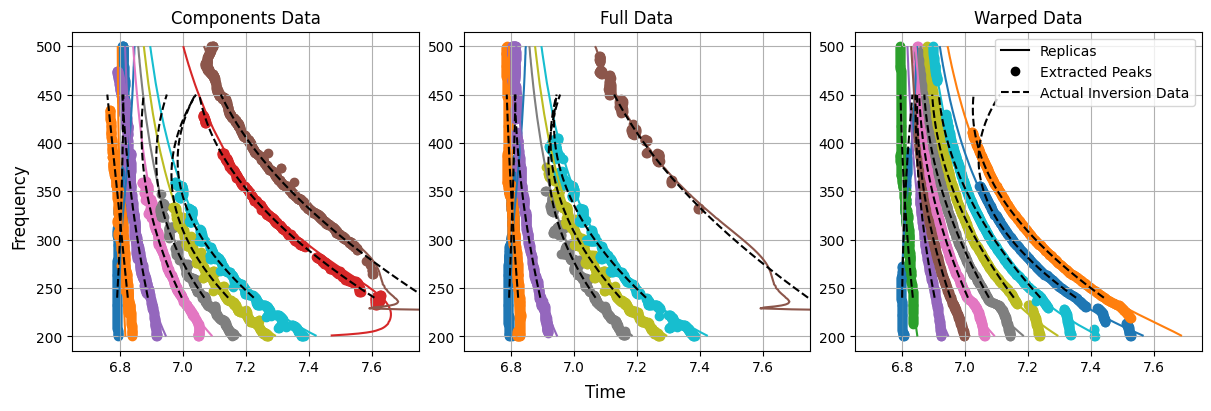

In [53]:
fig, (ax_comp, ax_full, ax_warped) = plt.subplots(1,3, layout="constrained")

for ind, p in enumerate(data_components['peaks_coordinates']):
    mode_no = data_components['mode_nos'][ind]
    color = f"C{mode_no}"
    ax_comp.scatter(p[:,1], p[:,0], c=color)
    ax_comp.plot(receiver_range/Vg[c==TRUE_SOUNDSPEED,mode_no,:].T, f_Vg, c=color)

ax_comp.set_prop_cycle(None)
ax_comp.plot(arrival_times_components.T, regression_fc, 'k--')

ax_comp.set_xlim([6.65, 7.75])

ax_comp.grid()

ax_comp.set_title("Components Data")

for ind, p in enumerate(data_full['peaks_coordinates']):
    mode_no = data_full['mode_nos'][ind]
    color = f"C{mode_no}"
    ax_full.scatter(p[:,1], p[:,0], c=color)
    ax_full.plot(receiver_range/Vg[c==TRUE_SOUNDSPEED,mode_no,:].T, f_Vg, c=color)
    
ax_full.set_prop_cycle(None)
ax_full.plot(arrival_times_full.T, regression_f, 'k--')

ax_full.set_xlim([6.65, 7.75])

ax_full.grid()

ax_full.set_title("Full Data")


for ind, p in enumerate(data_warped['peaks_coordinates']):
    mode_no = data_warped['mode_nos'][ind]
    color = f"C{mode_no}"
    ax_warped.scatter(p[:,1], p[:,0], c=color)
    ax_warped.plot(receiver_range/Vg[c==TRUE_SOUNDSPEED,mode_no,:].T, f_Vg, c=color)

ax_warped.set_prop_cycle(None)
ax_warped.plot(arrival_times_warped.T, regression_fw, 'k--')

ax_warped.set_xlim([6.65, 7.75])

ax_warped.grid()

ax_warped.set_title("Warped Data")

ax_warped.plot(0, 200, 'k-', label='Replicas')
ax_warped.plot(0, 200, 'ko', label='Extracted Peaks')
ax_warped.plot(0, 200, 'k--', label='Actual Inversion Data')

ax_warped.legend()



fig.supylabel("Frequency")
fig.supxlabel("Time")

fig.set_size_inches([12, 4])

In [54]:
fig.savefig("../data/output/mode_curves.png", dpi=600)

## Likelihoods

In [55]:
normalize = lambda x: x/np.sum(x)

In [56]:
l_comp = ai.AcousticInversionLikelihood(arrival_times_components[modes_comp])
l_full = ai.AcousticInversionLikelihood(arrival_times_full[modes_full])
l_warp = ai.AcousticInversionLikelihood(arrival_times_warped[:-2])

In [57]:
lk_comp = l_comp.likelihood(arrival_times_replica_comp[:, data_components['mode_nos'][modes_comp]], 1e0)
lk_full = l_full.likelihood(arrival_times_replica_full[:, data_full['mode_nos'][modes_full]], 1e0)
lk_warp = l_warp.likelihood(arrival_times_replica_warped[:, data_warped['mode_nos'][:-2]], 1e0)

In [58]:
lk_comp = normalize(lk_comp)
lk_full = normalize(lk_full)
lk_warp = normalize(lk_warp)

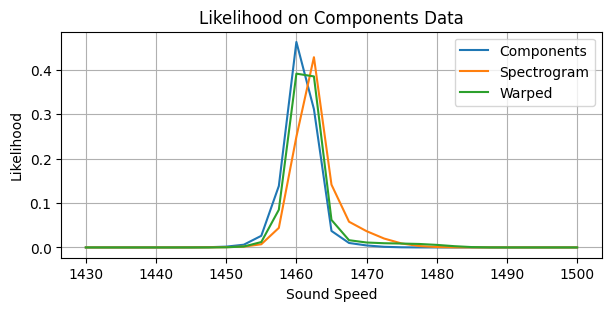

In [59]:
fig, ax = plt.subplots(layout="constrained")


ax.plot(c, lk_comp, label="Components")
ax.plot(c, lk_full, label="Spectrogram")
ax.plot(c, lk_warp, label="Warped")

ax.grid()

ax.legend()

ax.set_title("Likelihood on Components Data")

ax.set_xlabel("Sound Speed")
ax.set_ylabel("Likelihood")

fig.set_size_inches([6,3])

In [60]:
fig.savefig("../data/output/likelihood_deltas.png", dpi=600)

In [21]:
arrival_times_replica[c==TRUE_SOUNDSPEED][0]

NameError: name 'arrival_times_replica' is not defined

In [ ]:
residuals_components = ai.sensitivity_maps(arrival_times_components, arrival_times_replica[:,data_components['mode_nos']])
residuals_full = ai.sensitivity_maps(arrival_times_full, arrival_times_replica[:,data_full['mode_nos']])
residuals_warped = ai.sensitivity_maps(arrival_times_warped, arrival_times_replica[:,data_warped['mode_nos']])
residuals_replica = ai.sensitivity_maps(arrival_times_replica[c==TRUE_SOUNDSPEED][0], arrival_times_replica)

In [ ]:
fig, ax = plt.subplots(1,3, layout="constrained")

ax[0].semilogy(regression_f, residuals_components[0][c==TRUE_SOUNDSPEED][0][0:3].mT)
ax[1].semilogy(regression_f, residuals_full[0][c==TRUE_SOUNDSPEED][0][0:3].mT)
ax[2].semilogy(regression_f, residuals_warped[0][c==TRUE_SOUNDSPEED][0][0:3].mT)

for axnow in ax:
    axnow.set_ylim([5e-4, 1])

fig.set_size_inches([9.3,3])

In [ ]:
diff_components = np.abs(np.diff(residuals_components[0],axis=0)/np.diff(c)[:,np.newaxis,np.newaxis])
diff_full = np.abs(np.diff(residuals_full[0],axis=0)/np.diff(c)[:,np.newaxis,np.newaxis])
diff_warped = np.abs(np.diff(residuals_warped[0],axis=0)/np.diff(c)[:,np.newaxis,np.newaxis])
diff_replica = np.abs(np.diff(residuals_replica[0],axis=0)/np.diff(c)[:,np.newaxis,np.newaxis])

In [ ]:
fig, ax = plt.subplots(1,3, layout="constrained")


ax[0].semilogy(regression_f, diff_components.sum(0).mT)
ax[1].semilogy(regression_f, diff_full.sum(0).mT)
ax[2].semilogy(regression_f, diff_warped.sum(0).mT)

#for axnow in ax:
    #axnow.set_ylim([5e-4, 1])

fig.set_size_inches([9.3,3])

In [ ]:
fig, ax = plt.subplots(layout="constrained")

m1 = ax.pcolormesh(np.arange(1,18), regression_f, 10*np.log10(diff_replica.sum(0).mT), cmap="hot")

#for axnow in ax:
    #axnow.set_ylim([5e-4, 1])

plt.colorbar(m1,ax=ax)
fig.set_size_inches([5,3])